# 10 Anomalieerkennung ohne Labels

- Ziel: auffällig laufende Stationen benennen, ohne vorher ein Fehlerlabel zu vergeben.
- Grund: die Labels tragen nicht. Der überwachte Klassifikator bleibt mit Balanced Accuracy 0,33 bzw. 0,42 unter der Trivialrate 0,50 (`docs/ml-klassifikator.md`).
- Anomalie = Abweichung vom physikalisch erwartbaren Verhalten, die über mehrere Tage anhält. Fünf Detektoren im Vergleich.
- Prüfsignal ohne Labels: ein brauchbarer Score sinkt nach einer Begehung, bei Kontrollzählern im selben Zeitraum nicht.
- Logik in `src/dynamik.py`, `src/tagespanel.py`, `src/anomalie.py`, `src/regelkalibrierung.py`, Tests in den gleichnamigen Dateien unter `tests/`.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import anomalie as an
from src import clustervalidierung as cvl
from src import dynamik as dyn
from src import features as ft
from src import jahresvergleich as jv
from src import load_begehungen as lb
from src import load_data as ld
from src import nb00_daten as nb00
from src import regelkalibrierung as rk
from src import tagespanel as tp
from src import weather

from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

METER_DIR = ROOT / "data" / "processed" / "real_meters"
SPALTEN = {
    "Energy (kWh)": "energy", "Volume flow (l/h)": "flow",
    "Power (kW)": "power", "Temperature difference (°C)": "dt",
    "Flow temperature (°C)": "vl", "Return temperature (°C)": "rt",
    "Volume (m³)": "volume",
}
t0 = time.time()


def tick(txt):
    print(f"[{time.time() - t0:6.0f}s] {txt}")

## 1 Datenbasis

- Stundenreihen aus Notebook 00 (`data/processed/real_meters`): 100 Zähler, 31.05.2021 bis 20.07.2026. Fünf Zähler mit ODS-Nachlieferung bis Juli 2026, die übrigen bis 11.07.2025.
- Außentemperatur aus dem DWD-Cache über `src/weather.py` (45.008 Wetterstunden), als Prädiktor im Erwartungswertmodell und als Nenner der Effizienzkennzahl.

In [2]:
#Raster aus NB 00 unveraendert, nur leere Zaehlerstaende ergaenzt
serien = nb00.lade_serien(METER_DIR, leere_stunden_entfernen=False)
von = min(d.index[0] for d in serien.values() if len(d))
bis = max(d.index[-1] for d in serien.values() if len(d))
t_out = weather.load_outdoor_temperature(von, bis, allow_download=False)
tick(f"{len(serien)} Zaehlerreihen, {von:%Y-%m-%d} bis {bis:%Y-%m-%d}, "
     f"{len(t_out):,} Wetterstunden")

[    13s] 100 Zaehlerreihen, 2021-05-31 bis 2026-07-20, 45,008 Wetterstunden


## 2 Dynamikkennzahlen

- Hypothese: ein festsitzendes oder offenes Ventil zeigt sich als Rücklauf, der kaum auf Lastwechsel reagiert (erste Ableitung, K/h), ein defekter Regler als unruhiges Signal (zweite Ableitung).
- Dazu Kopplung Rücklauf–Vorlauf, Anteil praktisch stehender Rücklaufstunden (`rt_traege_anteil`) und Reaktionszeit auf Lastwechsel.
- Differenzen über einen fehlenden Zeitschritt werden verworfen.
- Beispiel unten: Zähler 41566330, 32.342 Stunden, Tagesdynamik an 972 von 1.349 Tagen.

In [3]:
beispiel = sorted(serien)[0]
reihe = serien[beispiel]
abl = dyn.ableitungen(reihe)
print(f"Zaehler {beispiel}: {len(reihe):,} Stunden")
print(abl[[c for c in abl.columns if c.startswith("rt_d")]].describe().round(3))
tag = dyn.tagesdynamik(reihe)
belegt = tag.dropna(subset=["rt_d1_abs_mean"])
print(f"\nTagesdynamik: {len(belegt)} von {len(tag)} Tagen belegt")
print(belegt.head(3).to_string(index=False))
print("\nSpalten:", list(tag.columns))

Zaehler 41566330: 32,342 Stunden
           rt_d1      rt_d2
count  23291.000  23277.000
mean       0.000      0.000
std        4.236      6.683
min      -29.400    -47.800
25%       -1.700     -2.300
50%       -0.100      0.100
75%        1.500      2.600
max       27.700     41.300

Tagesdynamik: 972 von 1349 Tagen belegt
     datum  rt_d1_abs_mean  rt_d1_abs_p95  rt_d2_abs_mean  rt_d2_abs_p95  rt_spanne_k  rt_traege_anteil  rt_vl_kopplung  n_dyn  n_last  reaktionszeit_h  n_lastwechsel
2022-11-13        3.675000          8.190        5.769565         14.180         17.6               NaN        0.337723     24       1              2.0              1
2022-11-14        4.166667          9.675        7.150000         15.450         16.5          0.000000        0.017035     24       4              0.0              3
2022-11-15        3.312500          9.780        5.916667         13.425         13.3          0.066667       -0.171547     24      15              1.0              9

Spalt

## 3 Stundencluster als Zustandsanteil

- Die fünf Betriebszustände aus Notebook 05 und 09 gehen als Zeitanteil je Station und Tag ins Panel ein (1.603.107 Stunden, 93 Zähler).
- Der Kurzschlussverdacht wird über das Zentroidprofil bestimmt (hoher Durchfluss, kleinste Spreizung), nicht über den seedabhängigen Index. Hier Cluster 4: Spreizung 3,8 K, Rücklauf 71 °C, 11,9 % der Stunden.

In [4]:
panel_h, ausschluss = cvl.lade_stundenpanel(METER_DIR)
panel_h = cvl.mit_kontext(panel_h, t_out)
X = StandardScaler().fit_transform(panel_h[cvl.BETRIEBS_FEATURES])
labels = cvl.fit_minibatch_kmeans(X, 5, n_init=10)
panel_h["cluster"] = labels
profil_h = cvl.zentroid_profil(panel_h[cvl.BETRIEBS_FEATURES].to_numpy(),
                               labels, cvl.BETRIEBS_FEATURES)
tick(f"Stundencluster: {len(panel_h):,} Stunden, "
     f"{panel_h['Zählernummer'].nunique()} Zaehler")
print(profil_h.round(2).to_string())

kandidat = profil_h[profil_h["flow_norm"] > 0.3]
KURZ = int(kandidat["dt"].idxmin())
ANTEIL = f"anteil_c{KURZ}"
print(f"\nKurzschlussverdacht ist Cluster {KURZ}, Spalte {ANTEIL}")

[    60s] Stundencluster: 1,603,107 Stunden, 93 Zaehler
         power_norm  flow_norm     dt     vl     rt  n_stunden  anteil_%
cluster                                                                 
0              0.33       0.22  33.72  67.09  33.32     392034      24.5
1              0.00       0.01   3.59  36.01  32.40     330042      20.6
2              0.07       0.10  11.82  66.92  55.06     408805      25.5
3              0.90       0.86  22.59  73.75  51.11     281021      17.5
4              0.20       0.78   3.80  75.23  71.39     191205      11.9

Kurzschlussverdacht ist Cluster 4, Spalte anteil_c4


## 4 Tagespanel

- Station × Tag als gemeinsame Basis aller Detektoren: Tageswerte der Messgrößen, Zustandsanteile, Dynamik, Tagesmitteltemperatur, Heizgradstunden.
- 105.513 Stationstage: 99,8 % mit genug Messstunden, 32 % ohne Laststunde, Dynamik für 68,7 %, Zustandsanteile für 81,1 %.
- `genug_stunden` markiert die auswertbaren Tage, nichts wird still verworfen.

In [5]:
panel = tp.baue_tagespanel(serien, stundencluster=panel_h, t_out=t_out)
tick(f"Tagespanel {panel.shape}, {panel['meter'].nunique()} Zaehler, "
     f"{panel['datum'].min():%Y-%m-%d} bis {panel['datum'].max():%Y-%m-%d}")
bilanz = tp.panelbilanz(panel)
print(bilanz.to_string(index=False))

[   607s] Tagespanel (105513, 43), 100 Zaehler, 2021-05-31 bis 2026-07-20
                 bedingung   tage   anteil
       Stationstage gesamt 105513 1.000000
         genug Messstunden 105313 0.998104
  Tag ohne jede Laststunde  33920 0.321477
         Dynamik gerechnet  72442 0.686569
 Zustandsanteile vorhanden  85585 0.811132
Aussentemperatur vorhanden 105439 0.999299


In [6]:
print("Spalten des Panels:")
for s in sorted(panel.columns):
    print("  ", s)

Spalten des Panels:
   anteil_c0
   anteil_c1
   anteil_c2
   anteil_c3
   anteil_c4
   datum
   dt_mean
   dt_mean_loaded
   energie_kwh
   flow_mean
   flow_median
   genug_stunden
   heizgradstunden
   last_anteil
   meter
   monat
   n_dyn
   n_last
   n_lastwechsel
   n_stunden
   n_stunden_basis
   n_stunden_cluster
   performance
   performance_gueltig
   power_max
   power_mean
   reaktionszeit_h
   rt_d1_abs_mean
   rt_d1_abs_p95
   rt_d2_abs_mean
   rt_d2_abs_p95
   rt_mean
   rt_mean_loaded
   rt_median
   rt_p95
   rt_spanne_k
   rt_traege_anteil
   rt_vl_kopplung
   season
   spreizung_k
   t_out_tag
   vl_mean
   volumen_m3


## 5 Erwartungswertmodell

- Zielgröße: Tagesmedian des Rücklaufs bei gegebener Außentemperatur und Last. Die Abweichung nach oben ist das Anomaliesignal.
- Netzweit (eine Regression für alle Stationen): „wer kühlt im Netzvergleich schlecht aus“. Schwäche: bauartbedingte Unterschiede fallen auf, ohne dass etwas defekt ist.
- Stationseigen (eine Regression je Station): „wann hat sich eine Station verschlechtert“. Schwäche: eine von Anfang an schlecht laufende Station wird zur eigenen Norm.

In [7]:
panel, info_netz = an.erwartungsmodell_netz(panel)
print("Netzweites Modell")
print(f"  Zielgroesse      {an.ZIEL}")
print(f"  Praediktoren     {list(an.PRAEDIKTOREN)}")
print(f"  Tage im Fit      {info_netz['n_tage']:,}")
print(f"  Stationen        {info_netz['n_stationen']}")
print(f"  r2               {info_netz['r2']:.3f}")
for name in info_netz["beta"]:
    print(f"  beta {name:<16} {info_netz['beta'][name]:+.3f}"
          f"  se {info_netz['se'][name]:.3f}  p {info_netz['p'][name]:.4f}")

panel, bilanz_station = an.erwartungsmodell_station(panel)
print(f"\nStationseigenes Modell: {int(bilanz_station['geschaetzt'].sum())} "
      f"von {len(bilanz_station)} Stationen geschaetzt")
nicht = bilanz_station[~bilanz_station["geschaetzt"]]
if len(nicht):
    print("nicht geschaetzt:")
    print(nicht["grund"].value_counts().to_string())
tick("Erwartungswertmodelle")

Netzweites Modell
  Zielgroesse      rt_median
  Praediktoren     ['t_out_tag', 'last_anteil', 'power_mean']
  Tage im Fit      94,329
  Stationen        100
  r2               0.046
  beta achsenabschnitt  +43.253  se 1.892  p 0.0000
  beta t_out_tag        +0.168  se 0.069  p 0.0165
  beta last_anteil      +2.066  se 1.901  p 0.2797
  beta power_mean       +0.088  se 0.011  p 0.0000

Stationseigenes Modell: 98 von 100 Stationen geschaetzt
nicht geschaetzt:
grund
Praediktoren linear abhaengig    2
[   608s] Erwartungswertmodelle


- Netzmodell: R² = 0,046 auf 94.329 Tagen. Mittlere Leistung (p < 0,001) und Außentemperatur (p = 0,017) tragen, der Lastanteil nicht (p = 0,28). Belastbar ist die Rangfolge, nicht der Absolutwert.
- Stationseigenes Modell für 98 von 100 Stationen. Sein Residuum mittelt per Konstruktion auf null und ist nur in Zeitfenstern aussagekräftig.

## 6 Weitere Detektoren

- Isolation Forest auf dem Tagespanel: 8 Merkmale, 60.277 Tage, 94 Stationen, contamination 0,05.
- Zustandsanteil: Zeitanteil im Kurzschlussverdacht, 17 von 93 Stationen im Mittel über 20 %.
- Dynamikscore: Summe robuster z-Werte aus Rücklauf-Vorlauf-Kopplung, `rt_traege_anteil` und zweiter Ableitung, prüft die Hypothese aus Abschnitt 2.

In [8]:
IF_MERKMALE = ["rt_median", "dt_mean_loaded", "t_out_tag", "last_anteil",
               "power_mean", "flow_median", "rt_d1_abs_mean", "rt_vl_kopplung"]
panel, info_if = an.score_isolation_forest(panel, IF_MERKMALE)
print(f"Isolation Forest: {info_if['n_tage']:,} Tage, "
      f"{len(info_if['merkmale'])} Merkmale, contamination "
      f"{info_if['contamination']}")

panel = an.score_zustand(panel, [ANTEIL])
zustand_je_station = panel.groupby("meter")[ANTEIL].mean().dropna()
print(f"Zeitanteil im Kurzschlussverdacht: {int((zustand_je_station > 0.2).sum())} "
      f"von {len(zustand_je_station)} Stationen ueber 20 Prozent")
panel, info_dyn = an.score_dynamik(panel)
print(f"Dynamikscore aus {info_dyn['benutzt']}")
for spalte, grund in info_dyn["verworfen"].items():
    print(f"  verworfen: {spalte} - {grund}")

DETEKTOREN = [f"score_{n}" for n in (an.D_RESID_NETZ, an.D_RESID_STATION,
                                     an.D_IFOREST, an.D_ZUSTAND, an.D_DYNAMIK)]
belegung = pd.DataFrame([
    {"detektor": d, "belegte_stationstage": int(panel[d].notna().sum()),
     "stationen": int(panel.loc[panel[d].notna(), "meter"].nunique())}
    for d in DETEKTOREN])
print()
print(belegung.to_string(index=False))
tick("Detektoren gebaut")

Isolation Forest: 60,277 Tage, 8 Merkmale, contamination 0.05
Zeitanteil im Kurzschlussverdacht: 17 von 93 Stationen ueber 20 Prozent
Dynamikscore aus ['rt_vl_kopplung', 'rt_d2_abs_mean']
  verworfen: rt_traege_anteil - MAD ueber alle Stationstage null, keine Streuung zu standardisieren

              detektor  belegte_stationstage  stationen
   score_residuum_netz                 94329        100
score_residuum_station                 91639         98
score_isolation_forest                 60277         94
  score_zustandsanteil                 85585         93
         score_dynamik                 72441        100
[   617s] Detektoren gebaut


- `rt_traege_anteil` fällt aus dem Dynamikscore: auf Tagesebene fast immer null, MAD über alle Stationstage null.
- Bei stündlicher Abtastung und 0,1 K Kanalauflösung ist ein stehender Rücklauf kaum beobachtbar. Die erhoffte Ventilkennzahl trägt im Tagespanel keine Information.

## 7 Übereinstimmung der Detektoren

- Vergleich auf Stationsebene: Spearman und Jaccard der jeweils 15 höchsten Stationen.
- Netzresiduum und Zustandsanteil am ähnlichsten (Spearman 0,67, Jaccard 0,43), Isolation Forest dazwischen (0,47 bzw. 0,48).
- Dynamikscore zu allen negativ korreliert (−0,06 bis −0,49), Top-15-Überschneidung höchstens 0,03.
- Stationseigenes Residuum: Stationsmittel per Konstruktion null, die Spearman 0,14 zum Netzresiduum ordnet Rundungsrauschen.

In [9]:
schwellen = {}
for d in DETEKTOREN:
    panel, s = an.persistente_tage(panel, d)
    schwellen[d] = s

scores = an.scoretabelle(panel, DETEKTOREN)
rang, jacc = an.uebereinstimmung(scores, DETEKTOREN, top_n=15)
print("Spearman ueber die Stationen:")
print(rang.round(2).to_string())
print("\nJaccard der Top 15:")
print(jacc.round(2).to_string())

Spearman ueber die Stationen:
                        score_residuum_netz  score_residuum_station  score_isolation_forest  score_zustandsanteil  score_dynamik
score_residuum_netz                    1.00                    0.14                    0.47                  0.67          -0.32
score_residuum_station                 0.14                    1.00                    0.19                  0.03          -0.32
score_isolation_forest                 0.47                    0.19                    1.00                  0.48          -0.49
score_zustandsanteil                   0.67                    0.03                    0.48                  1.00          -0.06
score_dynamik                         -0.32                   -0.32                   -0.49                 -0.06           1.00

Jaccard der Top 15:
                        score_residuum_netz  score_residuum_station  score_isolation_forest  score_zustandsanteil  score_dynamik
score_residuum_netz                    1.00   

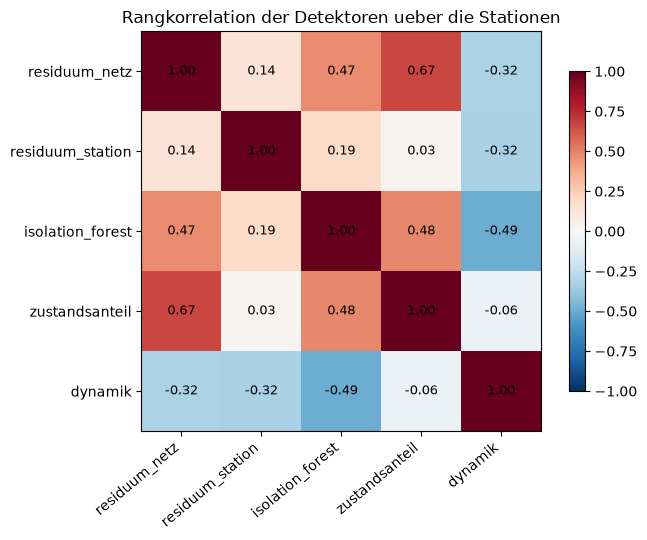

In [10]:
fig, ax = plt.subplots(figsize=(7, 5.5))
bild = ax.imshow(rang.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
kurz = [n.replace("score_", "") for n in rang.columns]
ax.set_xticks(range(len(kurz)), kurz, rotation=40, ha="right")
ax.set_yticks(range(len(kurz)), kurz)
for i in range(len(kurz)):
    for j in range(len(kurz)):
        ax.text(j, i, f"{rang.to_numpy()[i, j]:.2f}", ha="center",
                va="center", fontsize=9)
ax.set_title("Rangkorrelation der Detektoren ueber die Stationen")
fig.colorbar(bild, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

## 8 Persistenz

- Persistent auffällig: im 14-Tage-Fenster mindestens `min_tage` Tage (Standard 7) über der Tagesschwelle.
- Tagesschwelle: 90. Perzentil aller Stationstage (Netzresiduum 22,7 K).
- Netzresiduum ohne Filter: 43 Stationen mit Treffer, 14,6 % der Stationstage auffällig. Mit 7 von 14 Tagen: 29 Stationen, 8,6 % der Stationstage, 20 Stationen an mehr als 10 % ihrer Tage.

In [11]:
netz = f"score_{an.D_RESID_NETZ}"
zeilen = []
for min_tage in (1, 3, 5, 7, 10, 14):
    p2, _ = an.persistente_tage(panel, netz, schwelle=schwellen[netz],
                                fenster=14, min_tage=min_tage)
    tab = an.stationsscore(p2, netz)
    zeilen.append({"min_tage": min_tage,
                   "stationen_mit_treffer": int((tab["anteil_persistent"] > 0).sum()),
                   "stationen_ueber_10_prozent": int((tab["anteil_persistent"] > 0.10).sum()),
                   "anteil_persistenter_tage": float(p2[f"persistent_{netz}"].mean())})
persistenz = pd.DataFrame(zeilen)
print(f"Tagesschwellen (90. Perzentil): "
      + ", ".join(f"{k.replace('score_', '')} {v:.3f}" for k, v in schwellen.items()))
print()
print(persistenz.round(3).to_string(index=False))

Tagesschwellen (90. Perzentil): residuum_netz 22.718, residuum_station 8.208, isolation_forest 0.504, zustandsanteil 0.542, dynamik 1.158

 min_tage  stationen_mit_treffer  stationen_ueber_10_prozent  anteil_persistenter_tage
        1                     43                          24                     0.146
        3                     33                          24                     0.121
        5                     31                          24                     0.101
        7                     29                          20                     0.086
       10                     26                          17                     0.072
       14                     23                          14                     0.044


## 9 Validierung über die Begehungen

- Je Begehung ein Fensterpaar im Kernwinter vor und nach dem Eingriff, dieselben Fenster für Kontrollzähler ohne Begehung (wie Notebook 07).
- 58 Begehungen auf 56 Zählern, 49 Kontrollzähler, auswertbar n = 42 (Isolation Forest 41).
- Gepaarter Wilcoxon-Test und Diff-in-Diff gegen die Kontrollgruppe. Bestanden heißt: Diff-in-Diff negativ und p < 0,05.
- Zum Vergleich die Rohgrößen `rt_median` und `rt_mean_loaded` (Mittel nur über Laststunden).

In [12]:
zaehler = set(panel["meter"].unique())
begehungen = (lb.begehungen_mit_zaehler(available=zaehler)
              .dropna(subset=["meter", "datum"]))
begehungen["meter"] = begehungen["meter"].astype(int)
kontroll = sorted(zaehler - set(begehungen["meter"]))
cache = {}


def fenster(datum):
    key = pd.Timestamp(datum).normalize()
    if key not in cache:
        cache[key] = jv.winterfenster(key, jv.WINTER_KERN)
    return cache[key]


print(f"{len(begehungen)} Begehungen auf {begehungen['meter'].nunique()} "
      f"Zaehlern, {len(kontroll)} Kontrollzaehler")

zeilen = []
for d in DETEKTOREN + ["rt_median", "rt_mean_loaded"]:
    kennzahlen = (("score_mittel", "anteil_auffaellig")
                  if f"auffaellig_{d}" in panel.columns else ("score_mittel",))
    did = an.diff_in_diff(panel, d, begehungen, kontroll, fenster,
                          kennzahlen=kennzahlen)
    if len(did) == 0:
        print(f"{d}: kein auswertbares Fensterpaar")
        continue
    zeilen.append({"detektor": d, **an.validierungsbilanz(did, "score_mittel")})
validierung = pd.DataFrame(zeilen)
print()
print(validierung.round(4).to_string(index=False))
tick("Begehungsvalidierung")

58 Begehungen auf 56 Zaehlern, 49 Kontrollzaehler

              detektor     kennzahl  n  median_station  p_station  median_did  p_did  bestanden
   score_residuum_netz score_mittel 42         -1.1709     0.0385     -1.4252 0.0131       True
score_residuum_station score_mittel 42         -0.9882     0.1671     -1.4692 0.0362       True
score_isolation_forest score_mittel 41          0.0048     0.0560      0.0016 0.5997      False
  score_zustandsanteil score_mittel 42          0.0000     0.7007      0.0000 0.7007      False
         score_dynamik score_mittel 42          0.0060     0.9850      0.1102 0.2276      False
             rt_median score_mittel 42         -0.9929     0.0599     -1.4699 0.0102       True
        rt_mean_loaded score_mittel 41         -0.3407     0.2735     -0.2975 0.3343      False
[   652s] Begehungsvalidierung


- Bestanden: Netzresiduum (Diff-in-Diff −1,43, p = 0,013) und stationseigenes Residuum (−1,47, p = 0,036).
- Nicht bestanden: Isolation Forest (+0,002, p = 0,60, gepaart eher ein Anstieg), Zustandsanteil (Median 0, p = 0,70), Dynamikscore (+0,11, p = 0,23).
- `rt_median` allein liefert dasselbe (−1,47 K, p = 0,010), `rt_mean_loaded` nicht (p = 0,33). Der Effekt der Residuen kommt also großteils aus der Zielgröße.
- Einschränkung: alle auswertbaren Begehungen teilen dasselbe Fensterpaar im Kernwinter. Der Diff-in-Diff kontrolliert damit die Witterung, keinen begehungsspezifischen Zeiteffekt.

## 10 Plausibilisierung über den Energieeinsatz

- Frage: kostet eine hohe Punktzahl Energie?
- Kennzahl: Energie je Heizgradstunde (kWh/Kh) je Station, oberstes Quintil je Detektor gegen den Rest, Mann-Whitney.
- Gleicht Winterhärte und Historienlänge aus, nicht die Gebäudegröße.

In [13]:
eff = an.effizienz_je_station(panel)
tab = scores.merge(eff[["meter", "energie_je_kh"]], on="meter", how="left")
zeilen = []
for d in DETEKTOREN:
    s = tab[[d, "energie_je_kh"]].dropna()
    grenze = s[d].quantile(0.80)
    r = an.gruppenvergleich(s[s[d] >= grenze]["energie_je_kh"],
                            s[s[d] < grenze]["energie_je_kh"])
    zeilen.append({"detektor": d, **r})
effizienz = pd.DataFrame(zeilen)
print("kWh je Heizgradstunde, oberstes Quintil gegen Rest")
print(effizienz.round(4).to_string(index=False))

kWh je Heizgradstunde, oberstes Quintil gegen Rest
              detektor  n_hoch  n_niedrig  median_hoch  median_niedrig      p
   score_residuum_netz      20         80       0.2805          0.2094 0.0359
score_residuum_station      20         78       0.5477          0.1994 0.0000
score_isolation_forest      19         75       0.2821          0.2033 0.0034
  score_zustandsanteil      19         74       0.2789          0.2049 0.0890
         score_dynamik      20         80       0.1707          0.2805 0.0029


- Netzresiduum 0,28 gegen 0,21 kWh/Kh (p = 0,036), Isolation Forest 0,28 gegen 0,20 (p = 0,003), Zustandsanteil gleiche Richtung (p = 0,089).
- Stationseigenes Residuum (p < 0,001) ist ein Artefakt, das Quintil sortiert Stationsmittel, die per Konstruktion null sind.
- Dynamikscore umgekehrt: 0,17 gegen 0,28 (p = 0,003). Bildet eher Betriebsintensität oder Stationsgröße ab als Fehlverhalten.

## 11 Benennbares Muster je Station

- Jede Station bekommt ein Muster, woran die Auffälligkeit im Messsignal hängt. Beschreibung, keine Diagnose.
- Regeln auf Quantilen der Stationsmediane (p20/p80) statt absoluter Literaturschwellen.
- Ergebnis: 55 ohne eindeutiges Muster, 18 unruhige Regelung, 15 Rücklauf über Erwartung ohne weiteres Merkmal, 7 Ventilverdacht, 4 Kurzschlussverdacht, 1 Durchfluss ohne nennenswerte Abnahme.
- Von den 20 persistent auffälligen Stationen: 11 „Rücklauf über Erwartung“, 6 ohne Muster. Die Ventilregel greift knapp über der Auflösungsgrenze, nur eine dieser Stationen (66761022) ist persistent auffällig. „Unruhige Regelung“ hängt am durchgefallenen Dynamikscore.

In [14]:
PROFILSPALTEN = ["rt_vl_kopplung", "dt_mean_loaded", "rt_traege_anteil",
                 "rt_d1_abs_mean", "rt_d2_abs_mean", "flow_median",
                 "last_anteil", netz]
profil = an.stationsprofil(panel, PROFILSPALTEN)
muster = an.muster_je_station(profil)
print(muster["muster"].value_counts().to_string())

muster
kein eindeutiges Muster                                                55
unruhige Regelung                                                      18
Ruecklauf ueber Erwartung ohne weiteres Merkmal                        15
Ruecklauf reagiert kaum, Verdacht festsitzendes oder offenes Ventil     7
Ruecklauf folgt dem Vorlauf, Verdacht hydraulischer Kurzschluss         4
Durchfluss ohne nennenswerte Abnahme                                    1


In [15]:
stat = an.stationsscore(panel, netz)
treffer = stat[stat["anteil_persistent"] > 0.10].merge(muster, on="meter")
print(f"Stationen mit persistentem Befund ueber 10 Prozent der Tage: "
      f"{len(treffer)} von {panel['meter'].nunique()}")
print()
print(treffer.sort_values("anteil_persistent", ascending=False)
      [["meter", "score_mittel", "anteil_persistent", "max_lauf", "muster"]]
      .head(21).round(3).to_string(index=False))

Stationen mit persistentem Befund ueber 10 Prozent der Tage: 20 von 100

   meter  score_mittel  anteil_persistent  max_lauf                                                              muster
80912182        27.328              0.825       227                     Ruecklauf ueber Erwartung ohne weiteres Merkmal
72167782        26.398              0.766       298                     Ruecklauf ueber Erwartung ohne weiteres Merkmal
68956351        21.070              0.764       288                     Ruecklauf ueber Erwartung ohne weiteres Merkmal
72167793        23.950              0.620        45                     Ruecklauf ueber Erwartung ohne weiteres Merkmal
72135480        22.600              0.519       111     Ruecklauf folgt dem Vorlauf, Verdacht hydraulischer Kurzschluss
48090145        18.748              0.477        63                     Ruecklauf ueber Erwartung ohne weiteres Merkmal
68956360        11.783              0.474       174                     Ruecklauf ueber

## 12 Nachkalibrierung der Regel-Baseline

- Die Regel-Baseline in `src/fault_detection.py` passt nicht zu den echten Daten, einzelne Regeln treffen fast alle oder keine Station.
- Neue Schwelle je Regel: das Quantil, das rund 15 % der Stationen trifft. Die 15 % sind eine Setzung, angelehnt an 20 von 100 persistent auffälligen Stationen.
- `peak_load_share` braucht den Anschlusswert aus der Knotentabelle (85 von 100 Stationen).

In [16]:
nodes = ld.load_logical_nodes()
features = nb00.stationsfeatures(METER_DIR, nodes_df=nodes)
features = features.rename(columns={"Zählernummer": "meter"})
print(f"Stationsfeatures {features.shape}, Anschlusswert fuer "
      f"{int(features['anschlusswert_kw'].notna().sum())} von {len(features)} "
      f"Stationen")

neu, bilanz_rk = rk.kalibriere(features)
vn = rk.vorher_nachher(features, neu)
print()
print(vn.round(3).to_string(index=False))

Stationsfeatures (100, 24), Anschlusswert fuer 85 von 100 Stationen

                    schwelle             fehler                                     beschreibung  n_stationen  schwelle_alt  treffer_alt  anteil_alt  schwelle_neu  treffer_neu  anteil_neu
              rt_mean_winter          excess_rt                      Ruecklauf im Winter zu warm          100         48.00           38       0.380        58.877           15       0.150
    rt_above_50_share_loaded          excess_rt   Anteil Laststunden mit Ruecklauf ueber 50 Grad           98          0.30           62       0.633         0.902           15       0.153
        summer_flow_baseline    continuous_flow                       Mediandurchfluss im Sommer          100         25.00           27       0.270        65.650           15       0.150
     summer_idle_flow_median    continuous_flow           Durchfluss in lastfreien Sommerstunden          100         15.00           19       0.190        30.300           15    

In [17]:
print("Labelverteilung mit den alten Schwellen")
print(rk.labelverteilung(features).to_string())
print("\nLabelverteilung mit den kalibrierten Schwellen")
print(rk.labelverteilung(features, neu).to_string())
tick("Regelkalibrierung")

Labelverteilung mit den alten Schwellen
predicted_fault
control_hysteresis    47
excess_rt             38
fouled_filter          9
continuous_flow        4
healthy                2

Labelverteilung mit den kalibrierten Schwellen
predicted_fault
healthy               42
excess_rt             17
control_hysteresis    13
continuous_flow       10
fouled_filter         10
oversized_contract     6
low_spreading          2
[   671s] Regelkalibrierung


## 13 Was nicht getragen hat

- Isolation Forest findet teils dieselben Stationen wie das Netzresiduum, reagiert aber nicht auf den Eingriff. Mögliche Lesart, nicht geprüft: seltene Punkte sind eher Stillstands- oder Spitzentage als Tage mit schlechter Auskühlung.
- Zustandsanteil: gute beschreibende Kennzahl, kein Wirkungsmaß.
- Dynamikscore: Ventil- und Reglerhypothese auf diesen Daten nicht bestätigt. Wahrscheinlich ist die zweite Ableitung bei 0,1 K Auflösung großteils Quantisierungsrauschen.
- Alte Regelschwellen: `flow_short_cycle_power` 0,07 trifft 89 von 98 (kalibriert 0,291), `rt_above_50_share_loaded` 0,30 trifft 62 von 98 (kalibriert 0,902), `peak_load_share` 0,40 trifft keine (kalibriert 1,274, 13 von 85).

## 14 Export

- `data/processed/anomaliescores.csv`: Stationsscores mit Persistenz, Muster und Energie je Heizgradstunde.
- Dazu `anomalie_validierung.csv`, `regelkalibrierung.csv` und der Lauf-Kontext `anomaliescores.json`. Nur Zählernummern, keine Adressen.

In [18]:
AUS = ROOT / "data" / "processed"
AUS.mkdir(parents=True, exist_ok=True)

export = (scores.merge(stat[["meter", "anteil_auffaellig",
                             "anteil_persistent", "max_lauf"]],
                       on="meter", how="left")
                .merge(muster, on="meter", how="left")
                .merge(eff[["meter", "energie_je_kh"]], on="meter", how="left"))
export.to_csv(AUS / "anomaliescores.csv", index=False)
validierung.to_csv(AUS / "anomalie_validierung.csv", index=False)
vn.to_csv(AUS / "regelkalibrierung.csv", index=False)

kontext = {
    "stand": pd.Timestamp.now().strftime("%Y-%m-%d"),
    "zaehler": int(panel["meter"].nunique()),
    "stationstage": int(len(panel)),
    "zeitraum": [str(panel["datum"].min().date()), str(panel["datum"].max().date())],
    "zielgroesse": an.ZIEL,
    "praediktoren": list(an.PRAEDIKTOREN),
    "seed": an.SEED,
    "kurzschlusscluster": KURZ,
    "r2_netzmodell": float(info_netz["r2"]),
    "persistenz": {"fenster": an.PERSISTENZ_FENSTER,
                   "min_tage": an.PERSISTENZ_MIN_TAGE,
                   "schwellenquantil": an.SCHWELLENQUANTIL},
    "tagesschwellen": {k: float(v) for k, v in schwellen.items()},
    "validierung": validierung.set_index("detektor").to_dict(orient="index"),
    "zielanteil_regeln": rk.ZIELANTEIL,
    "stationen_persistent_ueber_10_prozent": int(len(treffer)),
}
(AUS / "anomaliescores.json").write_text(
    json.dumps(kontext, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"{len(export)} Stationen exportiert nach data/processed/")
print(export.head(5).round(3).to_string(index=False))

100 Stationen exportiert nach data/processed/
   meter  score_residuum_netz  score_residuum_station  score_isolation_forest  score_zustandsanteil  score_dynamik  anteil_auffaellig  anteil_persistent  max_lauf                                          muster                        begruendung  energie_je_kh
41566330               11.445                     0.0                   0.587                 0.042         -0.732              0.218              0.054        16 Ruecklauf ueber Erwartung ohne weiteres Merkmal score_residuum_netz 14.2 ueber p80          7.514
41566331               14.355                     0.0                     NaN                   NaN         -0.515              0.347              0.233        49 Ruecklauf ueber Erwartung ohne weiteres Merkmal score_residuum_netz 17.3 ueber p80          7.624
41566332               10.175                     0.0                     NaN                   NaN         -0.822              0.155              0.027        11 Ruecklau

## 15 Zusammenfassung & Bewertung

Ergebnis
- Netzresiduum und stationseigenes Residuum bestehen die Begehungsvalidierung (n = 42, 49 Kontrollzähler), drei Detektoren nicht. Netzweit für Ranglisten, stationseigen nur in Zeitfenstern.
- 20 von 100 Stationen sind an mehr als 10 % ihrer Tage persistent auffällig.

Belastbar
- Trefferliste plausibel: 68956351 (Ventil drei Jahre offen, Reparatur nicht in der Begehungstabelle) auf Rang 3, persistenter Anteil 0,764. Hinweis, keine Validierung.
- Auffällige Stationen brauchen mehr Energie je Heizgradstunde (Netzresiduum, Isolation Forest).
- Nach der Kalibrierung trifft jede Regel rund 15 % statt zwischen 0 und 91 %. Labelverteilung von 47 × `control_hysteresis` und 2 × `healthy` zu 42 × `healthy` und sechs Fehlerbildern. Das macht die Regeln bewertbar, nicht richtig.

Schwach
- Die Residuen bringen gegenüber dem rohen Tagesmedian des Rücklaufs keinen Validierungsgewinn.
- Diff-in-Diff eher ein verschobener gepaarter Test, R² des Netzmodells 0,046, Energie je Heizgradstunde nicht größenbereinigt.

Offen
- Zielquote von 15 % ist gesetzt, nicht entschieden.
- `peak_load_share` über 1,0: echte Lastspitzen oder zu niedrige Anschlusswerte in der Knotentabelle.
- Geprüft ist nur die Wirkung der Begehung auf den Rücklauf. Ob eine auffällige Station den zugeordneten Fehler hat, ist mit 57 Freitexten nicht zeigbar.
- Muster zu Maßnahme und Schweregrad braucht kodierte Freitexte (Notebook 15) oder Rückmeldung aus dem Betrieb.